# Telco Churn Classification — Revised Notebook

## 1. Objective and analysis plan

The main goal is to find the best supervised classification model **among the methods tested on this dataset**, then improve the selected model. The target is **Churn: Yes = 1 and No = 0**.

The flow is:
1. Check data types and missing values.
2. Examine numerical distributions and normality.
3. Check correlations and collinearity between predictors.
4. Split the data into **80% training and 20% testing**.
5. Compare Logistic Regression, KNN, Decision Tree, Random Forest, and HistGradientBoosting. LightGBM is an additional model.
6. Check generalization, class imbalance, and simple feature engineering.
7. Tune the best baseline method and evaluate the final results.

**F1 is the main selection score.** F1 balances precision and recall for churn customers. We also report ROC AUC, accuracy, precision, recall, specificity, false-positive rate, average precision, and confusion-matrix counts. A high accuracy alone is not enough when the classes are imbalanced.

Model selection uses five-fold cross-validation on training data. The test set is used at the end, after the model and settings have been chosen. The model comparison omits feature-by-feature churn summaries. Section 15 adds an illustrative business-impact scenario in Indonesian Rupiah.

`HG Boosting` is interpreted here as **HistGradientBoostingClassifier**. The additional LightGBM section can be skipped by setting `USE_LIGHTGBM = False`.

**Revision note:** this version uses F1 as the selection metric and a standard stratified 80/20 row split. The earlier notebook used average precision and grouped splitting. Results from those two protocols should not be read as a direct before/after performance comparison. The original notebook has been preserved.


In [1]:
# Run this once if the packages are not installed:
# %pip install pandas numpy matplotlib seaborn scipy statsmodels scikit-learn imbalanced-learn lightgbm

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from IPython.display import display

from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.model_selection import cross_validate, cross_val_predict, GridSearchCV, learning_curve
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix, make_scorer
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay
from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import Pipeline as ImbPipeline

USE_LIGHTGBM = True
if USE_LIGHTGBM:
    from lightgbm import LGBMClassifier

RANDOM_STATE = 42
pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

## 2. Data types and missing values

We load the supplied file and inspect its structure. Text columns should be categorical. `tenure` and `MonthlyCharges` should be numerical. Blank strings are treated as missing values, so they are not overlooked by `isna()`.

`No internet service` is a valid category, not a missing value. We will examine its redundancy with `InternetService` in the collinearity section.

In [2]:
df = pd.read_csv('data_telco_customer_churn.csv')

for column in df.select_dtypes(include='object').columns:
    df[column] = df[column].str.strip().replace('', np.nan)

display(df.head())
print('Rows and columns:', df.shape)
df.info()

data_check = pd.DataFrame({
    'Data type': df.dtypes,
    'Missing values': df.isna().sum(),
    'Missing %': df.isna().mean() * 100,
    'Unique values': df.nunique()
})
display(data_check)
print('Repeated full rows:', df.duplicated().sum())
print('Target values:', df['Churn'].unique())

,Dependents,tenure,OnlineSecurity,OnlineBackup,InternetService,DeviceProtection,TechSupport,Contract,PaperlessBilling,MonthlyCharges,Churn
0,Yes,9,No,No,DSL,Yes,Yes,Month-to-month,Yes,72.90,Yes
1,No,14,No,Yes,Fiber optic,Yes,No,Month-to-month,Yes,82.65,No
2,No,64,Yes,No,DSL,Yes,Yes,Two year,No,47.85,Yes
3,No,72,Yes,Yes,DSL,Yes,Yes,Two year,No,69.65,No
4,No,3,No internet service,No internet service,No,No internet service,No internet service,Month-to-month,Yes,23.60,No


Rows and columns: (4930, 11)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4930 entries, 0 to 4929
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Dependents        4930 non-null   object 
 1   tenure            4930 non-null   int64  
 2   OnlineSecurity    4930 non-null   object 
 3   OnlineBackup      4930 non-null   object 
 4   InternetService   4930 non-null   object 
 5   DeviceProtection  4930 non-null   object 
 6   TechSupport       4930 non-null   object 
 7   Contract          4930 non-null   object 
 8   PaperlessBilling  4930 non-null   object 
 9   MonthlyCharges    4930 non-null   float64
 10  Churn             4930 non-null   object 
dtypes: float64(1), int64(1), object(9)
memory usage: 423.8+ KB


,Data type,Missing values,Missing %,Unique values
Dependents,object,0,0.0,2
tenure,int64,0,0.0,73
OnlineSecurity,object,0,0.0,3
OnlineBackup,object,0,0.0,3
InternetService,object,0,0.0,3
DeviceProtection,object,0,0.0,3
TechSupport,object,0,0.0,3
Contract,object,0,0.0,3
PaperlessBilling,object,0,0.0,2
MonthlyCharges,float64,0,0.0,1422


Repeated full rows: 77
Target values: ['Yes' 'No']


**Cleaning decision:** there are no missing values in this file, so no rows need to be removed or filled for missingness. The model pipelines still include an imputer as a clear fallback for future missing inputs. It learns only from training data.

We retain the 77 repeated full rows because there is no customer ID: two customers can share the same recorded profile. The requested random row split may place similar or identical profiles in both sets. We quantify this limitation later and report a sensitivity check. It cannot establish independence at the customer level.

## 3. Numerical distributions and normality

We check descriptive statistics, histograms, Q–Q plots, skewness, and the Shapiro–Wilk test for `tenure` and `MonthlyCharges`.

- A roughly bell-shaped histogram and Q–Q points near the straight line support an approximately normal distribution.
- In the Shapiro test, **p < 0.05** indicates evidence against normality. A larger p-value does not prove normality.
- With thousands of observations, even small departures can produce a low p-value. We therefore read the plots and the test together.

These are descriptive checks. We do not choose transformations using test prediction performance.

,tenure,MonthlyCharges
count,4930.000000,4930.000000
mean,32.401217,64.883032
std,24.501193,29.923960
min,0.000000,18.800000
25%,9.000000,37.050000
50%,29.000000,70.350000
75%,55.000000,89.850000
max,72.000000,118.650000


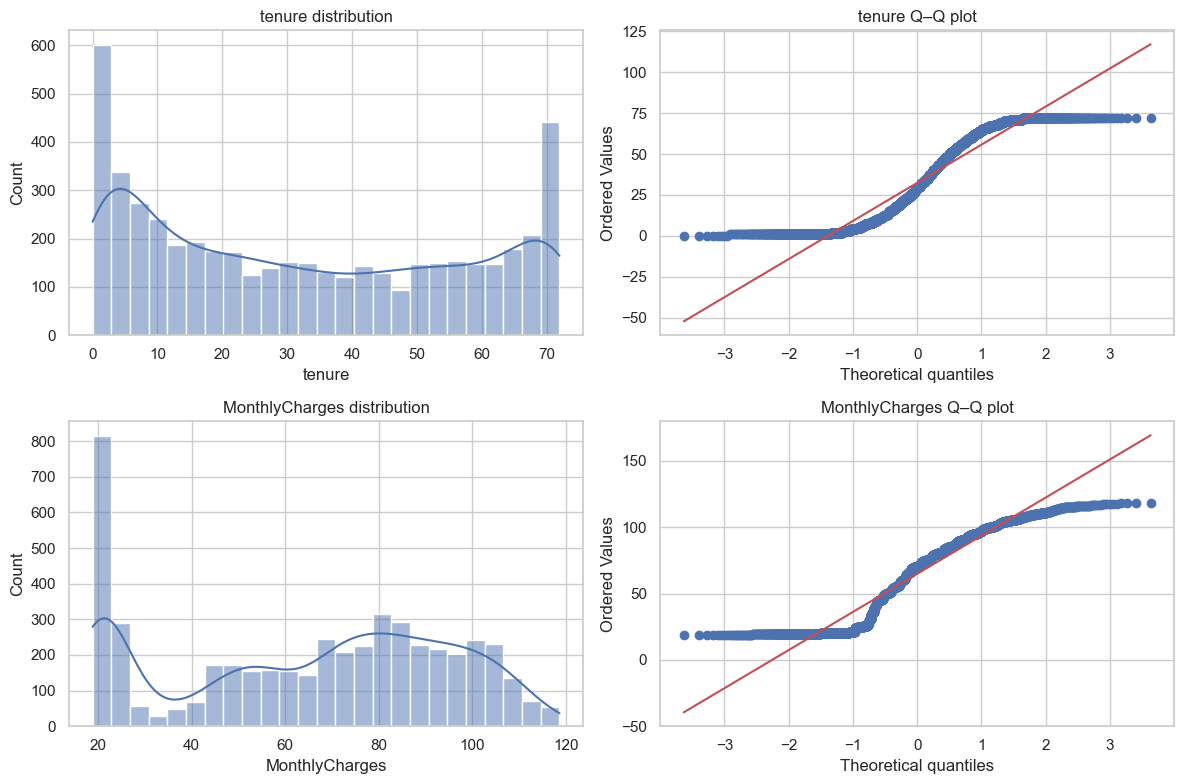

,Feature,Skewness,Shapiro statistic,p-value,Conclusion
0,tenure,0.235406,0.904764,3.835493e-48,Not normally distributed
1,MonthlyCharges,-0.225642,0.923044,1.148933e-44,Not normally distributed


In [3]:
numerical_columns = ['tenure', 'MonthlyCharges']
display(df[numerical_columns].describe())

normality_results = []
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for i, column in enumerate(numerical_columns):
    values = df[column].dropna()
    sns.histplot(values, bins=25, kde=True, ax=axes[i, 0])
    axes[i, 0].set_title(column + ' distribution')
    stats.probplot(values, dist='norm', plot=axes[i, 1])
    axes[i, 1].set_title(column + ' Q–Q plot')

    statistic, p_value = stats.shapiro(values)
    normality_results.append({
        'Feature': column,
        'Skewness': values.skew(),
        'Shapiro statistic': statistic,
        'p-value': p_value,
        'Conclusion': 'Not normally distributed' if p_value < 0.05 else 'Normality not rejected'
    })

plt.tight_layout()
plt.show()
normality_table = pd.DataFrame(normality_results)
display(normality_table)

**How this affects modeling:** neither predictor needs to be normally distributed for the models used here. Logistic Regression does not require normally distributed input features. KNN is sensitive to numerical scale, so we use `StandardScaler`. Scaling changes location and spread; it does **not** make a non-normal distribution normal. Tree-based models do not require normal predictors.

Tenure is bounded and measured in discrete periods, while monthly charges can reflect different service packages. We keep their original values and do not automatically remove observations or apply a logarithm just because the normality test rejects normality. The observed ranges are nonnegative, so zero tenure is retained as a possible new customer.

**Result:** both Shapiro p-values are far below 0.05 (tenure approximately 3.84 × 10⁻⁴⁸; monthly charges approximately 1.15 × 10⁻⁴⁴). Their skewness values are modest (0.24 and −0.23), but low skewness alone does not establish normality. The Q–Q plots show departures from the normal reference. We therefore describe both as non-normal, retain the observations, and apply scaling where needed rather than force a normal shape.

## 4. Predictor relationships and collinearity

Collinearity concerns relationships **between input features**, so `Churn` is excluded from this section. We use:

1. Pearson and Spearman correlation for the two numerical predictors.
2. Cramér's V for categorical pairs. This measures association from 0 to 1, not signed linear correlation.
3. VIF after one-hot encoding to check all numerical and categorical predictors together.

Pairwise association alone does not capture every multivariable dependency. VIF complements the pairwise checks. VIF above about 5 is a flag to investigate, not an automatic instruction to remove a feature. Exact redundancy can produce an infinite VIF.

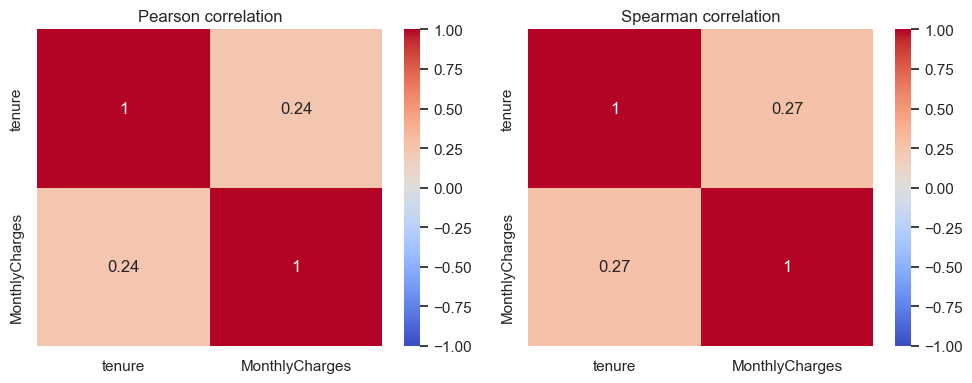

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, method in zip(axes, ['pearson', 'spearman']):
    correlation = df[numerical_columns].corr(method=method)
    sns.heatmap(correlation, annot=True, vmin=-1, vmax=1, cmap='coolwarm', ax=ax)
    ax.set_title(method.title() + ' correlation')
plt.tight_layout()
plt.show()

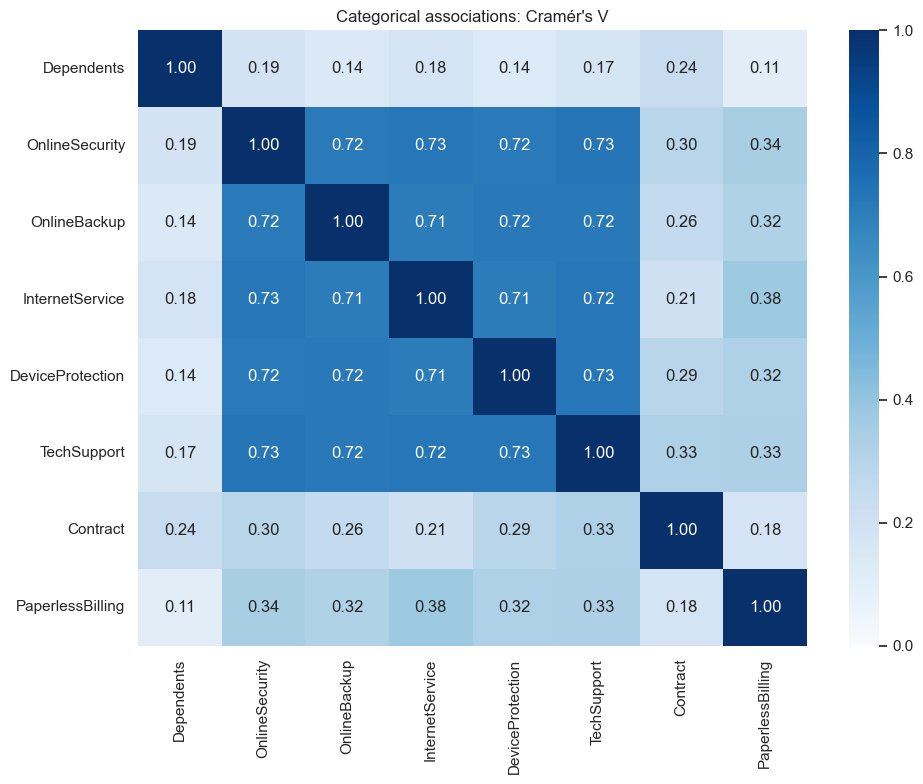

In [5]:
categorical_columns = df.drop(columns='Churn').select_dtypes(include='object').columns.tolist()

def cramers_v(first, second):
    table = pd.crosstab(first, second)
    chi_squared = stats.chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()
    denominator = min(table.shape) - 1
    return np.sqrt(chi_squared / (n * denominator))

category_association = pd.DataFrame(index=categorical_columns, columns=categorical_columns, dtype=float)

for first in categorical_columns:
    for second in categorical_columns:
        category_association.loc[first, second] = cramers_v(df[first], df[second])

plt.figure(figsize=(10, 8))
sns.heatmap(category_association, annot=True, fmt='.2f', vmin=0, vmax=1, cmap='Blues')
plt.title("Categorical associations: Cramér's V")
plt.tight_layout()
plt.show()

In [6]:
# Find exact duplicated columns after encoding the original predictors.
encoded_original = pd.get_dummies(df.drop(columns='Churn'), drop_first=True, dtype=float)
duplicate_columns = []

for i, first in enumerate(encoded_original.columns):
    for second in encoded_original.columns[i + 1:]:
        if encoded_original[first].equals(encoded_original[second]):
            duplicate_columns.append({'First column': first, 'Identical column': second})

display(pd.DataFrame(duplicate_columns))

,First column,Identical column
0,OnlineSecurity_No internet service,OnlineBackup_No internet service
1,OnlineSecurity_No internet service,InternetService_No
2,OnlineSecurity_No internet service,DeviceProtection_No internet service
3,OnlineSecurity_No internet service,TechSupport_No internet service
4,OnlineBackup_No internet service,InternetService_No
5,OnlineBackup_No internet service,DeviceProtection_No internet service
6,OnlineBackup_No internet service,TechSupport_No internet service
7,InternetService_No,DeviceProtection_No internet service
8,InternetService_No,TechSupport_No internet service
9,DeviceProtection_No internet service,TechSupport_No internet service


The `No internet service` dummy columns repeat the same information already recorded in `InternetService`. We use a simple representation: for the four add-on service columns, recode `No internet service` to `No`. `InternetService` still distinguishes customers without an internet connection.

This is a fixed, meaning-based recoding, not a learned transformation. It removes the duplicated absence-of-internet indicators without dropping the original service features. We use `drop='first'` when encoding categories to avoid the full-dummy/intercept dependency. The complete encoded VIF check appears after the split so it is based on training data.

In [7]:
service_columns = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport']

X = df.drop(columns='Churn').copy()
X[service_columns] = X[service_columns].replace('No internet service', 'No')
y = df['Churn'].map({'Yes': 1, 'No': 0})

## 5. Split the data: 80% training and 20% testing

`test_size=0.20` reserves 20% for testing. The remaining 80% is used for training and cross-validation. `stratify=y` keeps the churn proportions similar in both sets. `random_state=42` makes the split reproducible.

We use a standard row-level split as requested. Unlike the earlier notebook, this is not a grouped split. The test set is not used to choose a model, feature-engineering option, sampling method, or hyperparameter.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

split_table = pd.DataFrame({
    'Dataset': ['Training', 'Testing'],
    'Rows': [len(X_train), len(X_test)],
    'Share of data': [len(X_train) / len(X), len(X_test) / len(X)],
    'Churn rate': [y_train.mean(), y_test.mean()]
})
display(split_table)

# Count identical original profiles shared across the two sets.
original_profiles = pd.util.hash_pandas_object(df.drop(columns='Churn'), index=False)
test_profile_seen = original_profiles.loc[X_test.index].isin(original_profiles.loc[X_train.index])
print('Test rows with an identical original training profile:', test_profile_seen.sum())

,Dataset,Rows,Share of data,Churn rate
0,Training,3944,0.8,0.266988
1,Testing,986,0.2,0.266734


Test rows with an identical original training profile: 31


In [9]:
# VIF for every encoded training predictor, including the numerical columns.
encoded_train = pd.get_dummies(X_train, drop_first=True, dtype=float)
vif_input = sm.add_constant(encoded_train)

vif_results = []
for i, column in enumerate(vif_input.columns):
    if column != 'const':
        vif_results.append({
            'Encoded feature': column,
            'VIF': variance_inflation_factor(vif_input.to_numpy(), i)
        })

vif_table = pd.DataFrame(vif_results).sort_values('VIF', ascending=False)
display(vif_table)

,Encoded feature,VIF
1,MonthlyCharges,11.340424
5,InternetService_Fiber optic,5.560660
6,InternetService_No,3.426098
10,Contract_Two year,2.493621
0,tenure,2.335014
7,DeviceProtection_Yes,1.631179
9,Contract_One year,1.589439
8,TechSupport_Yes,1.568130
4,OnlineBackup_Yes,1.462142
3,OnlineSecurity_Yes,1.431601


VIF includes the relationships between numerical inputs and encoded categorical inputs. High values mean a coefficient may be unstable or difficult to interpret separately. They do not automatically mean poor predictive performance. We retain the remaining features and use regularized Logistic Regression, while comparing its validation performance with other models. This notebook focuses on prediction, not individual coefficient significance.

**VIF result:** after removing duplicated service-absence indicators, `MonthlyCharges` has VIF **11.34**, and the `InternetService_Fiber optic` indicator has VIF **5.56**. The remaining encoded features have VIF below 5. Charges and service type contain overlapping information. We keep both for prediction and use regularization in Logistic Regression; we do not interpret an individual coefficient as an isolated causal effect.

## 6. Preprocessor, pipelines, and evaluation metrics

The numerical pipeline fills any missing numeric inputs with the training median and scales the values. The categorical pipeline fills missing categories with the training mode and applies one-hot encoding. Every model uses its own copy of the preprocessor inside a pipeline.

This structure ensures that imputation, scaling, and encoding are fitted only on a training fold and then applied to its validation fold. We use the same five stratified folds for all algorithms.

| Metric | What it tells us |
|---|---|
| F1 | Balance of churn precision and recall; the primary selection metric |
| ROC AUC | Ability to rank churners above non-churners across thresholds |
| Accuracy | Proportion of all predictions that are correct |
| Precision | TP / (TP + FP): how many predicted churners actually churn |
| Recall / TPR | TP / (TP + FN): how many actual churners are detected |
| Specificity / TNR | TN / (TN + FP): how many non-churners are correctly excluded |
| False-positive rate | FP / (FP + TN): how many non-churners are incorrectly flagged |
| Average precision | Summary of the positive-class precision–recall curve |

TP = correctly predicted churn. TN = correctly predicted stay. FP = predicted churn but actually stayed. FN = predicted stay but actually churned. Higher FPR is worse.

In [10]:
numeric_preprocessor = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_preprocessor = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('numeric', numeric_preprocessor, numerical_columns),
    ('categorical', categorical_preprocessor, categorical_columns)
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scoring = {
    'F1': make_scorer(f1_score, zero_division=0),
    'ROC_AUC': 'roc_auc',
    'Accuracy': 'accuracy',
    'Precision': make_scorer(precision_score, zero_division=0),
    'Recall': 'recall',
    'Average_precision': 'average_precision'
}

def score_predictions(actual, probability, threshold=0.50, prediction=None):
    # Use supplied class labels, or apply a custom threshold when needed.
    if prediction is None:
        prediction = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(actual, prediction, labels=[0, 1]).ravel()

    return {
        'F1': f1_score(actual, prediction, zero_division=0),
        'ROC_AUC': roc_auc_score(actual, probability),
        'Accuracy': accuracy_score(actual, prediction),
        'Precision': precision_score(actual, prediction, zero_division=0),
        'Recall': recall_score(actual, prediction),
        'FPR': fp / (fp + tn),
        'Specificity': tn / (tn + fp),
        'Average_precision': average_precision_score(actual, probability),
        'TP': tp, 'TN': tn, 'FP': fp, 'FN': fn
    }

## 7. Compare classification methods on the training data

We compare five requested methods plus optional LightGBM. Each model initially uses its default predictive settings, except for a higher Logistic Regression iteration limit and 200 Random Forest trees. Fixed random seeds make randomized models repeatable.

Two tables are shown:
1. **Mean cross-validation scores:** used to select the best baseline model by F1.
2. **Out-of-fold predictions:** each training row is predicted by a model that did not train on that row. These give a single confusion matrix and FPR for each method. Pooled scores can differ slightly from the mean of fold scores.

The average training F1 and validation F1 also show possible overfitting. We do not choose the best model from training accuracy.

In [11]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    'KNN': KNeighborsClassifier(),
    'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=1),
    'HistGradientBoosting': HistGradientBoostingClassifier(early_stopping=False, random_state=RANDOM_STATE)
}

if USE_LIGHTGBM:
    models['LightGBM'] = LGBMClassifier(random_state=RANDOM_STATE, verbosity=-1, n_jobs=1)

pipelines = {}
cv_rows = []
oof_rows = []

for name, model in models.items():
    pipeline = Pipeline([
        ('preprocessor', clone(preprocessor)),
        ('model', clone(model))
    ])
    pipelines[name] = pipeline

    scores = cross_validate(
        pipeline, X_train, y_train,
        cv=cv, scoring=scoring, return_train_score=True, n_jobs=1
    )

    row = {'Model': name}
    for metric in scoring:
        row[metric] = scores['test_' + metric].mean()
    row['F1_std'] = scores['test_F1'].std()
    row['Train_F1'] = scores['train_F1'].mean()
    row['F1_gap'] = row['Train_F1'] - row['F1']
    cv_rows.append(row)

    oof_probability = cross_val_predict(
        pipeline, X_train, y_train,
        cv=cv, method='predict_proba', n_jobs=1
    )[:, 1]
    oof_rows.append({'Model': name, **score_predictions(y_train, oof_probability)})
    print(name, 'finished')

cv_table = pd.DataFrame(cv_rows).sort_values('F1', ascending=False).reset_index(drop=True)
oof_table = pd.DataFrame(oof_rows).sort_values('F1', ascending=False)
display(cv_table.round(4))
display(oof_table.round(4))

best_name = cv_table.loc[0, 'Model']
best_baseline = pipelines[best_name]
print('Best baseline method by mean CV F1:', best_name)
cv_table.to_csv('baseline_cv_scores.csv', index=False)

Logistic Regression finished


KNN finished


Decision Tree finished


Random Forest finished


HistGradientBoosting finished


LightGBM finished


,Model,F1,ROC_AUC,Accuracy,Precision,Recall,Average_precision,F1_std,Train_F1,F1_gap
0,Logistic Regression,0.5798,0.8387,0.7956,0.6432,0.5280,0.6545,0.0214,0.5812,0.0014
1,HistGradientBoosting,0.5681,0.8222,0.7860,0.6176,0.5270,0.6276,0.0361,0.7745,0.2064
2,LightGBM,0.5670,0.8232,0.7840,0.6107,0.5298,0.6298,0.0335,0.7840,0.2170
3,KNN,0.5445,0.7853,0.7776,0.6018,0.4976,0.5451,0.0098,0.6730,0.1285
4,Random Forest,0.5278,0.8019,0.7741,0.5974,0.4729,0.6003,0.0163,0.9883,0.4605
5,Decision Tree,0.4776,0.6440,0.7163,0.4692,0.4871,0.3670,0.0265,0.9882,0.5107


,Model,F1,ROC_AUC,Accuracy,Precision,Recall,FPR,Specificity,Average_precision,TP,TN,FP,FN
0,Logistic Regression,0.5798,0.8374,0.7956,0.6428,0.5280,0.1069,0.8931,0.6456,556,2582,309,497
4,HistGradientBoosting,0.5681,0.8210,0.7860,0.6160,0.5271,0.1197,0.8803,0.6160,555,2545,346,498
5,LightGBM,0.5671,0.8215,0.7840,0.6098,0.5299,0.1235,0.8765,0.6175,558,2534,357,495
1,KNN,0.5444,0.7849,0.7776,0.6009,0.4976,0.1204,0.8796,0.5435,524,2543,348,529
3,Random Forest,0.5266,0.8015,0.7726,0.5926,0.4739,0.1186,0.8814,0.5960,499,2548,343,554
2,Decision Tree,0.4792,0.6441,0.7145,0.4671,0.4919,0.2044,0.7956,0.3669,518,2300,591,535


Best baseline method by mean CV F1: Logistic Regression


**Benchmark result:** Logistic Regression has the highest mean validation F1, **0.5798**, followed by HistGradientBoosting (**0.5681**) and LightGBM (**0.5670**). These are five-fold training-data estimates at threshold 0.50. Logistic Regression is therefore the method we improve in the following sections. A different primary metric, split, or tuning effort can change the ranking.

## 8. Check generalization and class imbalance

**Overfitting:** a high training score with a noticeably lower validation score suggests the model has learned training-specific patterns.

**Underfitting:** low training and validation scores, relative to useful alternatives, suggest the model or features may be too limited. A small train–validation gap alone does not prove underfitting.

**Learning curve:** compare training and validation F1 as the training sample grows. Increasing validation scores suggest more data may help. A persistent large gap suggests regularization or less model complexity may help.

The dataset has more non-churners than churners. We calculate the majority-class accuracy baseline and inspect precision and recall rather than relying on accuracy alone. We do not balance the full dataset or the test set.

,Model,Train_F1,F1,F1_gap,F1_std
0,Logistic Regression,0.5812,0.5798,0.0014,0.0214
1,HistGradientBoosting,0.7745,0.5681,0.2064,0.0361
2,LightGBM,0.7840,0.5670,0.2170,0.0335
3,KNN,0.6730,0.5445,0.1285,0.0098
4,Random Forest,0.9883,0.5278,0.4605,0.0163
5,Decision Tree,0.9882,0.4776,0.5107,0.0265


,Count,Percentage
No churn (0),2891,73.301217
Churn (1),1053,26.698783


Always predicting No gives accuracy: 0.733
But it gives churn recall = 0 and F1 = 0.


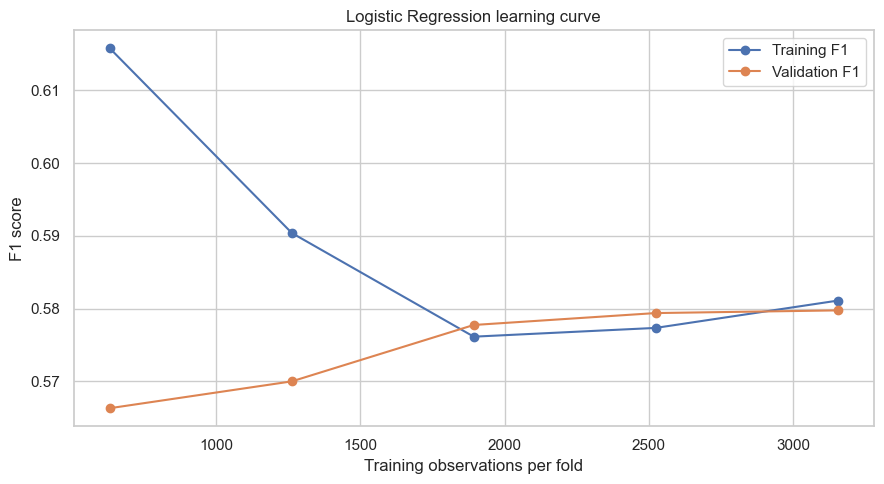

In [12]:
generalization_table = cv_table[['Model', 'Train_F1', 'F1', 'F1_gap', 'F1_std']].copy()
display(generalization_table.round(4))

class_table = pd.DataFrame({
    'Count': y_train.value_counts().sort_index(),
    'Percentage': y_train.value_counts(normalize=True).sort_index() * 100
})
class_table.index = ['No churn (0)', 'Churn (1)']
display(class_table)
print('Always predicting No gives accuracy:', round((y_train == 0).mean(), 4))
print('But it gives churn recall = 0 and F1 = 0.')

sizes, train_scores, validation_scores = learning_curve(
    best_baseline, X_train, y_train,
    cv=cv, scoring='f1', train_sizes=[0.2, 0.4, 0.6, 0.8, 1.0],
    shuffle=True, random_state=RANDOM_STATE, n_jobs=1
)

plt.figure(figsize=(9, 5))
plt.plot(sizes, train_scores.mean(axis=1), 'o-', label='Training F1')
plt.plot(sizes, validation_scores.mean(axis=1), 'o-', label='Validation F1')
plt.xlabel('Training observations per fold')
plt.ylabel('F1 score')
plt.title(best_name + ' learning curve')
plt.legend()
plt.tight_layout()
plt.show()

**Generalization result:** Logistic Regression's training F1 is **0.5812** and validation F1 is **0.5798**, a gap of only **0.0014**. This does not show a substantial overfitting gap, but the moderate score leaves room for improvement. We cannot conclude underfitting from the small gap alone. Decision Tree and Random Forest show much larger gaps (**0.5107** and **0.4605**), providing clear evidence that their default training performance does not generalize well in this split.

## 9. Test simple feature engineering and imbalance handling

Feature engineering is relevant if a useful relationship can be represented more clearly. It must earn its place through validation rather than be added automatically.

We test two simple features together:
- `tenure_group`: 0–12, 13–24, 25–48, or more than 48 months.
- `service_count`: the number of Yes values in the four add-on service columns.

These features are derived only from existing predictors. We keep the original features, so the additions may be redundant. Validation decides whether to keep this feature set. The experiment measures their combined effect, not the isolated effect of each feature.

We also test **RandomOverSampler**, which repeats minority-class training observations. It is placed inside an imbalanced-learn pipeline, so resampling happens only during training within each fold. Validation and test distributions remain unchanged.

Four options are compared for the selected method: original features, engineered features, oversampling, and both together. Each uses the same folds and F1 metric.

In [13]:
def add_features(data):
    result = data.copy()
    result['tenure_group'] = pd.cut(
        result['tenure'],
        bins=[-1, 12, 24, 48, np.inf],
        labels=['0-12', '13-24', '25-48', '49-plus']
    ).astype(object)
    result['service_count'] = (result[service_columns] == 'Yes').sum(axis=1)
    return result

engineered_preprocessor = ColumnTransformer([
    ('numeric', clone(numeric_preprocessor), numerical_columns + ['service_count']),
    ('categorical', clone(categorical_preprocessor), categorical_columns + ['tenure_group'])
])

variants = {}
for use_features in [False, True]:
    for use_sampling in [False, True]:
        name = 'Features=' + str(use_features) + ', Oversampling=' + str(use_sampling)
        steps = []

        if use_features:
            steps.append(('features', FunctionTransformer(add_features)))
            selected_preprocessor = clone(engineered_preprocessor)
        else:
            selected_preprocessor = clone(preprocessor)

        steps.append(('preprocessor', selected_preprocessor))
        if use_sampling:
            steps.append(('sampler', RandomOverSampler(random_state=RANDOM_STATE)))
        steps.append(('model', clone(models[best_name])))
        variants[name] = ImbPipeline(steps)

variant_rows = []
for name, pipeline in variants.items():
    scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    row = {'Variant': name}
    for metric in scoring:
        row[metric] = scores['test_' + metric].mean()
    variant_rows.append(row)

variant_table = pd.DataFrame(variant_rows).sort_values('F1', ascending=False).reset_index(drop=True)
display(variant_table.round(4))
best_variant_name = variant_table.loc[0, 'Variant']
best_variant = variants[best_variant_name]
print('Best preparation option:', best_variant_name)

,Variant,F1,ROC_AUC,Accuracy,Precision,Recall,Average_precision
0,"Features=True, Oversampling=True",0.6208,0.8398,0.7442,0.5138,0.7844,0.6550
1,"Features=False, Oversampling=True",0.6194,0.8376,0.7409,0.5095,0.7901,0.6525
2,"Features=False, Oversampling=False",0.5798,0.8387,0.7956,0.6432,0.5280,0.6545
3,"Features=True, Oversampling=False",0.5672,0.8412,0.7949,0.6504,0.5033,0.6571


Best preparation option: Features=True, Oversampling=True


**Preparation result:** feature engineering with oversampling has the highest validation F1 (**0.6208**). Oversampling without the added features is very close (**0.6194**). Adding features alone lowers F1 to **0.5672**, compared with **0.5798** for the baseline. Most of the improvement therefore comes from the change in class treatment and the resulting precision–recall balance; the extra value of these engineered features is small and is not established as a stable gain.

The selected preparation includes both additions and RandomOverSampler. We do not also add balanced class weights in the tuning grid, because oversampling already balances the training classes.

## 10. Hyperparameter tuning for the selected method

We now tune the **same method that won the baseline comparison**, using the best preparation option from the previous step. `GridSearchCV` tests combinations of settings on the training folds and selects the highest mean F1.

The parameter dictionary includes relevant settings for whichever method wins. Only the selected method's grid is executed. The `model__` prefix means the setting belongs to the pipeline step named `model`.

| Method | Settings and purpose |
|---|---|
| Logistic Regression | `C`: regularization strength (smaller means stronger); `penalty`: L1 or L2; class weights |
| KNN | Number of neighbors, uniform/distance voting, Manhattan/Euclidean distance |
| Decision Tree | Maximum depth, minimum leaf size, class weights |
| Random Forest | Number of trees, maximum depth, minimum leaf size, class weights |
| HistGradientBoosting | Learning rate, iterations, leaf count, L2 regularization, class weights |
| LightGBM | Learning rate, trees, leaves, minimum leaf size, class weights |

Balanced class weights are tested where available if the selected preparation does not already oversample. We avoid automatically combining both balancing methods. The seed is fixed, not optimized. These are small, interpretable grids for a learning project, not an exhaustive search.

This sequential workflow is simple: select a preparation option, then tune the model. It may miss interactions that a joint search would find. Cross-validation results used for selection can be optimistic; the untouched test set is the final check.

In [14]:
using_oversampling = 'sampler' in best_variant.named_steps
class_weights = [None] if using_oversampling else [None, 'balanced']

parameter_grids = {
    'Logistic Regression': {
        'model__C': [0.01, 0.1, 1, 10, 100],
        'model__penalty': ['l1', 'l2'],
        'model__solver': ['liblinear'],
        'model__class_weight': class_weights
    },
    'KNN': {
        'model__n_neighbors': [5, 11, 21, 35],
        'model__weights': ['uniform', 'distance'],
        'model__p': [1, 2]
    },
    'Decision Tree': {
        'model__max_depth': [3, 5, 10, None],
        'model__min_samples_leaf': [1, 5, 20],
        'model__class_weight': class_weights
    },
    'Random Forest': {
        'model__n_estimators': [100, 200],
        'model__max_depth': [5, 10, None],
        'model__min_samples_leaf': [1, 5, 15],
        'model__class_weight': class_weights
    },
    'HistGradientBoosting': {
        'model__learning_rate': [0.03, 0.1],
        'model__max_iter': [100, 200],
        'model__max_leaf_nodes': [7, 15],
        'model__l2_regularization': [0, 10],
        'model__class_weight': class_weights
    },
    'LightGBM': {
        'model__learning_rate': [0.03, 0.1],
        'model__n_estimators': [100, 200],
        'model__num_leaves': [7, 15],
        'model__min_child_samples': [20, 60],
        'model__class_weight': class_weights
    }
}

param_grid = parameter_grids[best_name]
display(pd.Series(param_grid, name='Values to test').to_frame())

grid_search = GridSearchCV(
    best_variant,
    param_grid=param_grid,
    scoring=scoring,
    refit='F1',
    cv=cv,
    n_jobs=1,
    return_train_score=True
)
grid_search.fit(X_train, y_train)

print('Best parameters:', grid_search.best_params_)
print('Best tuning CV F1:', round(grid_search.best_score_, 4))
search_results = pd.DataFrame(grid_search.cv_results_)
display(search_results[['params', 'mean_train_F1', 'mean_test_F1', 'std_test_F1',
                        'mean_test_ROC_AUC', 'mean_test_Precision', 'mean_test_Recall']]
        .sort_values('mean_test_F1', ascending=False).head(10))

# Keep the untuned variant if the search fails to improve its validation F1.
if grid_search.best_score_ > variant_table.loc[0, 'F1']:
    improved_model = clone(grid_search.best_estimator_)
    improvement_choice = 'Best preparation + tuned parameters'
else:
    improved_model = clone(best_variant)
    improvement_choice = 'Best preparation; tuning did not improve CV F1'

print('Configuration retained:', improvement_choice)

,Values to test
model__C,"[0.01, 0.1, 1, 10, 100]"
model__penalty,"[l1, l2]"
model__solver,[liblinear]
model__class_weight,[None]


Best parameters: {'model__C': 0.1, 'model__class_weight': None, 'model__penalty': 'l1', 'model__solver': 'liblinear'}
Best tuning CV F1: 0.6216


,params,mean_train_F1,mean_test_F1,std_test_F1,mean_test_ROC_AUC,mean_test_Precision,mean_test_Recall
2,"{'model__C': 0.1, 'model__class_weight': None,...",0.625224,0.621603,0.012874,0.839063,0.514437,0.785367
3,"{'model__C': 0.1, 'model__class_weight': None,...",0.627678,0.620769,0.010976,0.839846,0.515761,0.779666
5,"{'model__C': 1, 'model__class_weight': None, '...",0.626615,0.620336,0.010642,0.839749,0.513111,0.784419
6,"{'model__C': 10, 'model__class_weight': None, ...",0.626437,0.619659,0.011415,0.839801,0.512196,0.784419
7,"{'model__C': 10, 'model__class_weight': None, ...",0.626427,0.619659,0.011415,0.839808,0.512196,0.784419
4,"{'model__C': 1, 'model__class_weight': None, '...",0.626262,0.619226,0.009217,0.839703,0.511200,0.785367
8,"{'model__C': 100, 'model__class_weight': None,...",0.626376,0.619192,0.011390,0.839801,0.511555,0.784419
9,"{'model__C': 100, 'model__class_weight': None,...",0.626128,0.618967,0.011446,0.839785,0.511259,0.784419
1,"{'model__C': 0.01, 'model__class_weight': None...",0.625606,0.614640,0.020691,0.837798,0.515725,0.760668
0,"{'model__C': 0.01, 'model__class_weight': None...",0.605466,0.606144,0.021478,0.825314,0.485057,0.808134


Configuration retained: Best preparation + tuned parameters


**Tuning result:** the best grid configuration is `C=0.1`, `penalty='l1'`, `solver='liblinear'`, and `class_weight=None`, with the selected feature engineering and oversampling. The grid evaluates **10 combinations × 5 folds = 50 fits**, followed by refitting the winning setting. L1 regularization can shrink some coefficients to zero; `C=0.1` applies stronger regularization than `C=1`.

Validation F1 increases from **0.6208** for the preparation-only model to **0.6216** after tuning. This is a small observed increase of about **0.08 percentage points**, not a large proven improvement. We retain it under the predefined maximum-F1 rule.

## 11. Generalization after improvement

We compare the original winner, the selected preparation option, and the final configuration using the same training folds. This separates the effect of feature engineering/resampling from the additional effect of parameter tuning. If two rows are equal, that stage did not produce an additional retained change.

Cross-validation training scores for oversampled pipelines are evaluated on the original training-fold observations, rather than on an enlarged balanced copy. This makes the displayed training and validation metrics easier to compare.

In [15]:
stages = {
    'Baseline': best_baseline,
    'Best preparation': best_variant,
    'Final configuration': improved_model
}

stage_rows = []
for name, pipeline in stages.items():
    scores = cross_validate(
        pipeline, X_train, y_train,
        cv=cv, scoring=scoring, return_train_score=True, n_jobs=1
    )
    stage_rows.append({
        'Stage': name,
        'Train F1': scores['train_F1'].mean(),
        'Validation F1': scores['test_F1'].mean(),
        'F1 gap': scores['train_F1'].mean() - scores['test_F1'].mean(),
        'Validation ROC AUC': scores['test_ROC_AUC'].mean(),
        'Validation precision': scores['test_Precision'].mean(),
        'Validation recall': scores['test_Recall'].mean()
    })

stage_table = pd.DataFrame(stage_rows)
display(stage_table.round(4))

,Stage,Train F1,Validation F1,F1 gap,Validation ROC AUC,Validation precision,Validation recall
0,Baseline,0.5812,0.5798,0.0014,0.8387,0.6432,0.5280
1,Best preparation,0.6267,0.6208,0.0059,0.8398,0.5138,0.7844
2,Final configuration,0.6252,0.6216,0.0036,0.8391,0.5144,0.7854


## 12. Optional threshold adjustment

By default we predict churn when the score is at least 0.50. A different threshold can improve F1 without changing the fitted model. We test thresholds from 0.10 to 0.70 using **training out-of-fold predictions only**. We keep the highest F1, with ties favoring the higher threshold.

This is separate from hyperparameter tuning. It changes precision, recall, and confusion counts; it does not change ROC AUC or average precision because the probability scores stay the same. This development estimate reuses data that supported model selection, so the final test comparison remains important.

In [16]:
improved_oof = cross_val_predict(
    improved_model, X_train, y_train,
    cv=cv, method='predict_proba', n_jobs=1
)[:, 1]

threshold_rows = []
for threshold in np.round(np.arange(0.10, 0.71, 0.05), 2):
    threshold_rows.append({
        'Threshold': threshold,
        **score_predictions(y_train, improved_oof, threshold)
    })

threshold_table = pd.DataFrame(threshold_rows).sort_values(
    ['F1', 'Threshold'], ascending=[False, False]
)
best_threshold = threshold_table.iloc[0]['Threshold']
display(threshold_table[['Threshold', 'F1', 'Precision', 'Recall', 'FPR']].round(4))
print('Selected threshold:', best_threshold)

,Threshold,F1,Precision,Recall,FPR
8,0.50,0.6216,0.5143,0.7854,0.2701
9,0.55,0.6181,0.5299,0.7417,0.2397
11,0.65,0.6160,0.5913,0.6429,0.1619
10,0.60,0.6147,0.5546,0.6895,0.2017
7,0.45,0.6127,0.4882,0.8224,0.3141
6,0.40,0.6044,0.4639,0.8670,0.3649
12,0.70,0.5965,0.6352,0.5622,0.1176
5,0.35,0.5921,0.4400,0.9050,0.4196
4,0.30,0.5802,0.4224,0.9259,0.4611
3,0.25,0.5637,0.4020,0.9430,0.5109


Selected threshold: 0.5


**Threshold result:** the best tested development threshold remains **0.50**. Therefore threshold adjustment adds no further change in this run. Keeping the default threshold is a valid result; an extra tuning step does not have to produce an improvement.

## 13. Final evaluation on the 20% test set

All model-development choices are now fixed. First, we show the test scores of the baseline methods for reference. We do not change the selected method based on this table. Then we compare the winner before preparation changes, after preparation, after tuning, and after threshold adjustment.

This distinction matters: an improvement caused by oversampling must not be presented as an improvement caused only by hyperparameter tuning. Some metrics can improve while others become worse.

### Reading the familiar training and prediction steps

The next cell uses the same explicit sequence for every model:

```python
fitted_model = clone(pipeline)
fitted_model.fit(X_train, y_train)
y_train_pred = fitted_model.predict(X_train)
y_test_pred = fitted_model.predict(X_test)
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)
```

The loop runs this sequence once for each model name. `.fit()` trains the pipeline, `.predict()` returns class labels, and `accuracy_score()` compares those labels with the actual outcomes. The training scores here are in-sample scores from fitting all training rows; they differ from the fold-level scores in Section 7. They are shown for diagnosis, not model selection.

We also call `.predict_proba()` because ROC AUC and average precision require scores rather than class labels. For a custom threshold, we convert these probabilities into labels explicitly. Some classifiers can resolve an exact 0.50 tie differently from `probability >= 0.50`; the ordinary model comparison uses `.predict()` consistently.

Section 7 still uses `cross_validate()` for fair model selection. It calls `.fit()` and the required prediction methods internally on each fold. The explicit final-test code is shown here after all model choices are frozen, to keep the test data out of development decisions.


In [17]:
# Train and evaluate each baseline model using explicit steps.
test_rows = []
train_rows = []
baseline_probabilities = {}
baseline_predictions = {}

for name, pipeline in pipelines.items():
    # 1. Create a fresh copy of the model pipeline.
    fitted_model = clone(pipeline)

    # 2. Train the preprocessor and model on training data only.
    fitted_model.fit(X_train, y_train)

    # 3. Predict class labels: 0 = no churn, 1 = churn.
    y_train_pred = fitted_model.predict(X_train)
    y_test_pred = fitted_model.predict(X_test)

    # 4. Predict scores for ROC AUC and average precision.
    y_train_proba = fitted_model.predict_proba(X_train)[:, 1]
    y_test_proba = fitted_model.predict_proba(X_test)[:, 1]

    # 5. Calculate accuracy explicitly.
    train_accuracy = accuracy_score(y_train, y_train_pred)
    test_accuracy = accuracy_score(y_test, y_test_pred)

    # 6. Calculate the test confusion matrix and other metrics.
    tn, fp, fn, tp = confusion_matrix(y_test, y_test_pred, labels=[0, 1]).ravel()

    test_rows.append({
        'Model': name,
        'F1': f1_score(y_test, y_test_pred, zero_division=0),
        'ROC_AUC': roc_auc_score(y_test, y_test_proba),
        'Accuracy': test_accuracy,
        'Precision': precision_score(y_test, y_test_pred, zero_division=0),
        'Recall': recall_score(y_test, y_test_pred),
        'FPR': fp / (fp + tn),
        'Specificity': tn / (tn + fp),
        'Average_precision': average_precision_score(y_test, y_test_proba),
        'TP': tp, 'TN': tn, 'FP': fp, 'FN': fn
    })

    train_rows.append({
        'Model': name,
        'Training accuracy': train_accuracy,
        'Test accuracy': test_accuracy,
        'Training F1': f1_score(y_train, y_train_pred, zero_division=0),
        'Test F1': f1_score(y_test, y_test_pred, zero_division=0),
        'Training ROC AUC': roc_auc_score(y_train, y_train_proba),
        'Test ROC AUC': roc_auc_score(y_test, y_test_proba)
    })

    baseline_probabilities[name] = y_test_proba
    baseline_predictions[name] = y_test_pred
    print(f'{name}: training accuracy = {train_accuracy:.4f}, test accuracy = {test_accuracy:.4f}')

train_test_table = pd.DataFrame(train_rows)
test_table = pd.DataFrame(test_rows).sort_values('F1', ascending=False)
display(train_test_table.round(4))
display(test_table.round(4))

# Evaluate the selected method at each improvement stage.
baseline_probability = baseline_probabilities[best_name]
baseline_prediction = baseline_predictions[best_name]

prepared_model = clone(best_variant)
prepared_model.fit(X_train, y_train)
prepared_prediction = prepared_model.predict(X_test)
prepared_probability = prepared_model.predict_proba(X_test)[:, 1]
prepared_accuracy = accuracy_score(y_test, prepared_prediction)

improved_model.fit(X_train, y_train)
improved_prediction = improved_model.predict(X_test)
improved_probability = improved_model.predict_proba(X_test)[:, 1]
improved_accuracy = accuracy_score(y_test, improved_prediction)

# A custom threshold needs probabilities instead of the default .predict() rule.
final_prediction = (improved_probability >= best_threshold).astype(int)
final_accuracy = accuracy_score(y_test, final_prediction)

print('Preparation-stage accuracy:', round(prepared_accuracy, 4))
print('After tuning accuracy:', round(improved_accuracy, 4))
print('Final-threshold accuracy:', round(final_accuracy, 4))

# Reuse the metric helper for this comparison to avoid repeating every formula.
comparison_rows = [
    {'Stage': 'Baseline at 0.50',
     **score_predictions(y_test, baseline_probability, prediction=baseline_prediction)},
    {'Stage': 'Best preparation at 0.50',
     **score_predictions(y_test, prepared_probability, prediction=prepared_prediction)},
    {'Stage': 'After tuning decision at 0.50',
     **score_predictions(y_test, improved_probability, prediction=improved_prediction)},
    {'Stage': 'Final threshold ' + str(best_threshold),
     **score_predictions(y_test, improved_probability, prediction=final_prediction)}
]
comparison_table = pd.DataFrame(comparison_rows)
display(comparison_table.round(4))

metric_columns = ['F1', 'ROC_AUC', 'Accuracy', 'Precision', 'Recall', 'FPR', 'Specificity', 'Average_precision']
change_table = comparison_table.set_index('Stage')[metric_columns].diff().iloc[1:] * 100
change_table.index.name = 'Change from the preceding stage (percentage points)'
display(change_table.round(2))

train_test_table.to_csv('explicit_train_test_scores.csv', index=False)
test_table.to_csv('baseline_test_scores.csv', index=False)
comparison_table.to_csv('improvement_test_scores.csv', index=False)


Logistic Regression: training accuracy = 0.7946, test accuracy = 0.7961


KNN: training accuracy = 0.8370, test accuracy = 0.7657


Decision Tree: training accuracy = 0.9926, test accuracy = 0.7373


Random Forest: training accuracy = 0.9926, test accuracy = 0.7779


HistGradientBoosting: training accuracy = 0.8717, test accuracy = 0.8083


LightGBM: training accuracy = 0.8722, test accuracy = 0.7992


,Model,Training accuracy,Test accuracy,Training F1,Test F1,Training ROC AUC,Test ROC AUC
0,Logistic Regression,0.7946,0.7961,0.5790,0.5939,0.8409,0.8556
1,KNN,0.8370,0.7657,0.6697,0.5295,0.8969,0.7935
2,Decision Tree,0.9926,0.7373,0.9861,0.5350,0.9999,0.6869
3,Random Forest,0.9926,0.7779,0.9862,0.5389,0.9997,0.8233
4,HistGradientBoosting,0.8717,0.8083,0.7478,0.6330,0.9456,0.8495
5,LightGBM,0.8722,0.7992,0.7480,0.6118,0.9497,0.8472


,Model,F1,ROC_AUC,Accuracy,Precision,Recall,FPR,Specificity,Average_precision,TP,TN,FP,FN
4,HistGradientBoosting,0.6330,0.8495,0.8083,0.6468,0.6198,0.1231,0.8769,0.6599,163,634,89,100
5,LightGBM,0.6118,0.8472,0.7992,0.6316,0.5932,0.1259,0.8741,0.6483,156,632,91,107
0,Logistic Regression,0.5939,0.8556,0.7961,0.6336,0.5589,0.1176,0.8824,0.6735,147,638,85,116
3,Random Forest,0.5389,0.8233,0.7779,0.6038,0.4867,0.1162,0.8838,0.6066,128,639,84,135
2,Decision Tree,0.5350,0.6869,0.7373,0.5068,0.5665,0.2006,0.7994,0.4055,149,578,145,114
1,KNN,0.5295,0.7935,0.7657,0.5702,0.4943,0.1355,0.8645,0.5348,130,625,98,133


Preparation-stage accuracy: 0.7475
After tuning accuracy: 0.7485
Final-threshold accuracy: 0.7485


,Stage,F1,ROC_AUC,Accuracy,Precision,Recall,FPR,Specificity,Average_precision,TP,TN,FP,FN
0,Baseline at 0.50,0.5939,0.8556,0.7961,0.6336,0.5589,0.1176,0.8824,0.6735,147,638,85,116
1,Best preparation at 0.50,0.6278,0.8570,0.7475,0.5172,0.7985,0.2711,0.7289,0.6851,210,527,196,53
2,After tuning decision at 0.50,0.6320,0.8576,0.7485,0.5182,0.8099,0.2739,0.7261,0.6844,213,525,198,50
3,Final threshold 0.5,0.6320,0.8576,0.7485,0.5182,0.8099,0.2739,0.7261,0.6844,213,525,198,50


,F1,ROC_AUC,Accuracy,Precision,Recall,FPR,Specificity,Average_precision
Change from the preceding stage (percentage points),,,,,,,,
Best preparation at 0.50,3.39,0.14,-4.87,-11.64,23.95,15.35,-15.35,1.16
After tuning decision at 0.50,0.42,0.06,0.10,0.10,1.14,0.28,-0.28,-0.07
Final threshold 0.5,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


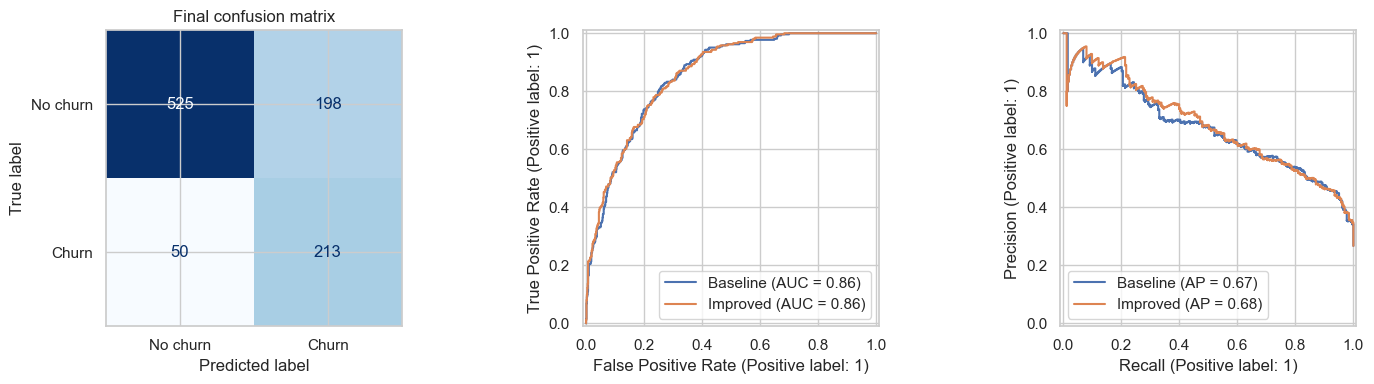

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, improved_probability >= best_threshold,
    display_labels=['No churn', 'Churn'],
    cmap='Blues', colorbar=False, ax=axes[0]
)
axes[0].set_title('Final confusion matrix')

RocCurveDisplay.from_predictions(y_test, baseline_probability, name='Baseline', ax=axes[1])
RocCurveDisplay.from_predictions(y_test, improved_probability, name='Improved', ax=axes[1])

PrecisionRecallDisplay.from_predictions(y_test, baseline_probability, name='Baseline', ax=axes[2])
PrecisionRecallDisplay.from_predictions(y_test, improved_probability, name='Improved', ax=axes[2])

plt.tight_layout()
plt.show()

### Sensitivity to repeated profiles

The standard 80/20 split has 31 test rows whose original predictor profile is also present in training. This does not prove they are the same customer, but it limits how confidently we can interpret the test set as entirely new customers.

Below we also evaluate the frozen final model on the remaining test rows. This is a sensitivity check, not a second model-selection step. A future project with customer IDs should use a grouped split, or a time-based split if the goal is future churn prediction.

In [19]:
unseen_profile = ~test_profile_seen.to_numpy()

sensitivity_table = pd.DataFrame([
    {'Sample': 'All test rows', 'Rows': len(y_test),
     **score_predictions(y_test, improved_probability, best_threshold)},
    {'Sample': 'Test rows without a matching training profile', 'Rows': unseen_profile.sum(),
     **score_predictions(y_test.iloc[unseen_profile], improved_probability[unseen_profile], best_threshold)}
])
display(sensitivity_table.round(4))

,Sample,Rows,F1,ROC_AUC,Accuracy,Precision,Recall,FPR,Specificity,Average_precision,TP,TN,FP,FN
0,All test rows,986,0.6320,0.8576,0.7485,0.5182,0.8099,0.2739,0.7261,0.6844,213,525,198,50
1,Test rows without a matching training profile,955,0.6262,0.8582,0.7487,0.5102,0.8105,0.2730,0.7270,0.6811,201,514,193,47


**Held-out result:** at the unchanged 0.50 threshold, baseline Logistic Regression finds **147** churners with **85** false positives. The final configuration finds **213** churners with **198** false positives. It detects **66 more churners**, but also produces **113 more false alarms**.

F1 rises from **0.5939 to 0.6320** (+3.81 percentage points overall), and recall from **55.89% to 80.99%**. Precision falls from **63.36% to 51.82%**, accuracy from **79.61% to 74.85%**, and FPR rises from **11.76% to 27.39%**. ROC AUC moves only slightly, from **0.8556 to 0.8576**.

The preparation step contributes about **+3.39 F1 percentage points** on this test set, while the additional parameter-tuning step contributes about **+0.42 points**. Threshold tuning adds zero. These are observed changes on one split; small differences have not been established as statistically reliable. The table separates them so the entire gain is not incorrectly credited to hyperparameter tuning.

## 14. Conclusion

The tables above answer which baseline method performs best by cross-validation F1, how preparation and tuning change its performance, and what trade-offs appear on the test set.

The selected method is best under this dataset, split, metric, and tested settings. We tuned only the baseline winner, so this is not proof that every other method would lose after its own tuning. The absence of dates and customer IDs also limits claims about future deployment. Section 15 translates the prediction outcomes into illustrative financial estimates; those estimates are assumptions, not measured retention outcomes.

Read the final summary below together with the confusion counts. Higher recall means more churners detected; lower precision means more false alarms. A threshold change should not be confused with an increase in ranking quality.

In [20]:
print('Best baseline method:', best_name)
print('Selected preparation:', best_variant_name)
print('Retained configuration:', improvement_choice)
print('Selected threshold:', best_threshold)
print()

baseline_result = comparison_table.iloc[0]
tuned_result = comparison_table.iloc[2]
final_result = comparison_table.iloc[3]

for metric in ['F1', 'ROC_AUC', 'Accuracy', 'Precision', 'Recall', 'FPR']:
    print(f'{metric}: baseline={baseline_result[metric]:.4f}, '
          f'after tuning decision={tuned_result[metric]:.4f}, '
          f'final threshold={final_result[metric]:.4f}')

print()
print('Overall test F1 change:', round((final_result['F1'] - baseline_result['F1']) * 100, 2), 'percentage points')
print('Final TP, TN, FP, FN:', int(final_result['TP']), int(final_result['TN']), int(final_result['FP']), int(final_result['FN']))

Best baseline method: Logistic Regression
Selected preparation: Features=True, Oversampling=True
Retained configuration: Best preparation + tuned parameters
Selected threshold: 0.5

F1: baseline=0.5939, after tuning decision=0.6320, final threshold=0.6320
ROC_AUC: baseline=0.8556, after tuning decision=0.8576, final threshold=0.8576
Accuracy: baseline=0.7961, after tuning decision=0.7485, final threshold=0.7485
Precision: baseline=0.6336, after tuning decision=0.5182, final threshold=0.5182
Recall: baseline=0.5589, after tuning decision=0.8099, final threshold=0.8099
FPR: baseline=0.1176, after tuning decision=0.2739, final threshold=0.2739

Overall test F1 change: 3.81 percentage points
Final TP, TN, FP, FN: 213 525 198 50


## 15. Business impact in Indonesian Rupiah

### Business question

Does a campaign using the improved model produce more net contribution than a campaign using the baseline model?

**Before** means contacting all customers predicted to churn by the baseline model at 0.50. **After** means contacting all customers predicted to churn by the final improved model at the selected threshold. The selected threshold in this run is also 0.50. Both policies use the same 986 test observations and identical economic assumptions. They have different contact volumes, so this is not an equal-budget comparison.

The actual labels let us count the historical churners each model identifies. They do not tell us whether an offer would retain those customers. The following calculations are **illustrative scenarios in Rp**, not realized savings, forecasts, or a currency conversion. We do not relabel the dataset's `MonthlyCharges` as Rupiah.

### Editable assumptions

We assume a 20% **incremental prevention rate among contacted would-be churners**, relative to no campaign. This is not simply the percentage of contacted customers who remain. We assume the same effect for both shortlists and no incremental benefit for customers who would stay anyway.

Each prevented churn preserves six additional months of **Rp150,000 monthly contribution** after normal service costs, before campaign costs. The combined contact and offer expense is **Rp50,000 per contacted customer**, including false positives. Because this cost already includes the offer, we do not deduct it twice. These values are demonstration inputs, not estimates from the file.

In [21]:
# Edit these assumptions to match the company's real campaign economics.
retention_success_rate = 0.20
monthly_contribution_rp = 150_000
additional_months_retained = 6
cost_per_contact_rp = 50_000

# Format numbers as Rupiah for display; calculations still use numeric values.
def rupiah(value):
    return 'Rp' + f'{value:,.0f}'.replace(',', '.')

assumptions_table = pd.DataFrame({
    'Assumption': [
        'Incremental churn-prevention rate',
        'Monthly contribution per retained customer',
        'Additional months retained',
        'Combined contact and offer cost per customer'
    ],
    'Illustrative value': [
        f'{retention_success_rate:.0%}',
        rupiah(monthly_contribution_rp),
        str(additional_months_retained),
        rupiah(cost_per_contact_rp)
    ]
})
display(assumptions_table)

,Assumption,Illustrative value
0,Incremental churn-prevention rate,20%
1,Monthly contribution per retained customer,Rp150.000
2,Additional months retained,6
3,Combined contact and offer cost per customer,Rp50.000


### Calculation logic

1. **Customers contacted = TP + FP.** Every predicted-positive customer receives the campaign.
2. **Expected additional customers retained = TP × incremental prevention rate.** This is equivalent to contacts × shortlist precision × incremental prevention rate.
3. **Retained contribution = additional customers retained × monthly contribution × additional months retained.**
4. **Campaign cost = contacts × combined contact and offer cost.**
5. **Net incremental contribution = retained contribution − campaign cost.** This is incremental to no campaign, whose incremental benefit and expense are both zero in the scenario.
6. **Improvement from the model change = after net contribution − before net contribution.**

Expected customer counts can be fractional because they represent averages under an assumed intervention effect. Counts of identified churners are observations, while prevented churn and Rupiah outcomes are modeled assumptions.

In [22]:
# Use the predictions already evaluated above. No models are retrained here.
before_counts = score_predictions(
    y_test, baseline_probability, prediction=baseline_prediction
)
after_counts = score_predictions(
    y_test, improved_probability, prediction=final_prediction
)

business_rows = []
for name, counts in [('Before: baseline model', before_counts),
                     ('After: improved model', after_counts)]:
    contacts = counts['TP'] + counts['FP']
    expected_retained = counts['TP'] * retention_success_rate
    retained_contribution = expected_retained * monthly_contribution_rp * additional_months_retained
    campaign_cost = contacts * cost_per_contact_rp
    net_contribution = retained_contribution - campaign_cost

    business_rows.append({
        'Campaign': name,
        'Customers contacted': contacts,
        'Actual churners identified': counts['TP'],
        'False positives contacted': counts['FP'],
        'Expected additional customers retained': expected_retained,
        'Retained contribution (Rp)': retained_contribution,
        'Campaign cost (Rp)': campaign_cost,
        'Net contribution (Rp)': net_contribution
    })

business_table = pd.DataFrame(business_rows).set_index('Campaign')
business_comparison = business_table.T
business_comparison['Change: after minus before'] = (
    business_comparison['After: improved model'] - business_comparison['Before: baseline model']
)

# Only the displayed version is formatted. business_table remains numeric.
display_table = business_comparison.astype(object)
for row in display_table.index:
    if '(Rp)' in row:
        display_table.loc[row] = business_comparison.loc[row].map(rupiah)
    elif 'Expected' in row:
        display_table.loc[row] = business_comparison.loc[row].map(lambda value: f'{value:.1f}')
    else:
        display_table.loc[row] = business_comparison.loc[row].map(lambda value: f'{value:.0f}')
display(display_table)

before_business = business_table.loc['Before: baseline model']
after_business = business_table.loc['After: improved model']
net_increase = after_business['Net contribution (Rp)'] - before_business['Net contribution (Rp)']
print('Change in expected net contribution:', rupiah(net_increase))
business_table.to_csv('business_impact_rupiah.csv')

Campaign,Before: baseline model,After: improved model,Change: after minus before
Customers contacted,232,411,179
Actual churners identified,147,213,66
False positives contacted,85,198,113
Expected additional customers retained,29.4,42.6,13.2
Retained contribution (Rp),Rp26.460.000,Rp38.340.000,Rp11.880.000
Campaign cost (Rp),Rp11.600.000,Rp20.550.000,Rp8.950.000
Net contribution (Rp),Rp14.860.000,Rp17.790.000,Rp2.930.000


Change in expected net contribution: Rp2.930.000


### Visual 1: explain the change in net contribution

The waterfall chart starts with the baseline campaign's net contribution. Green shows additional retained contribution, orange shows additional campaign expense, and dark green shows the improved campaign's net result. The chart separates benefit from cost instead of presenting extra detections as free revenue.

The vertical axis uses **Rp million** for readability. Labels show the full Rupiah amounts. Values are conditional on the editable assumptions above.

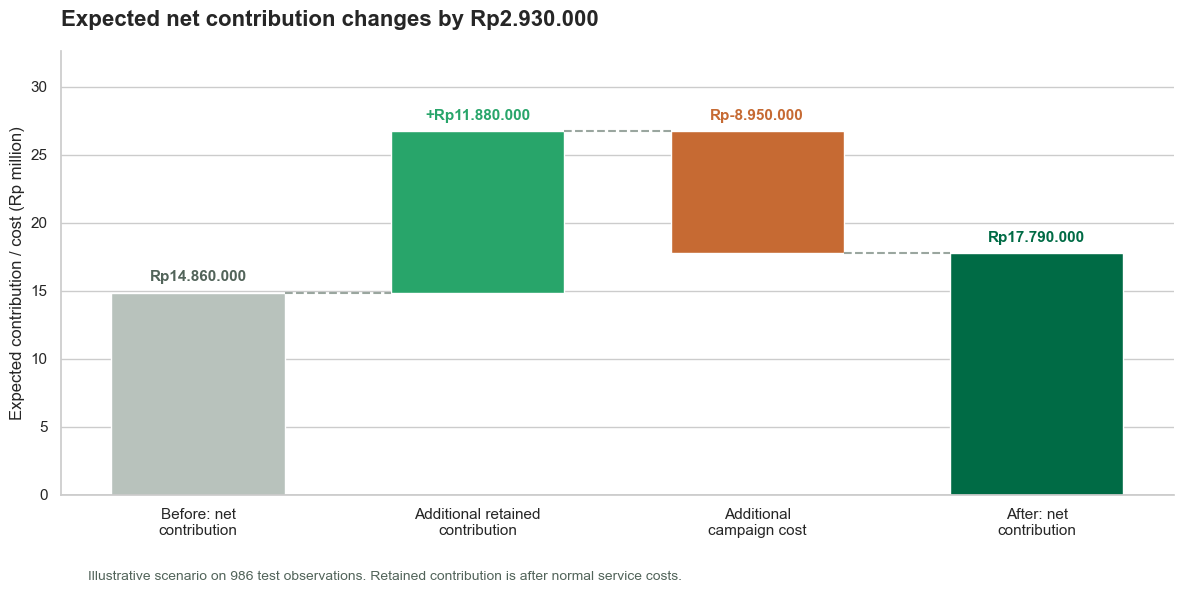

In [23]:
from matplotlib.ticker import FuncFormatter

before_net = before_business['Net contribution (Rp)']
after_net = after_business['Net contribution (Rp)']
extra_contribution = after_business['Retained contribution (Rp)'] - before_business['Retained contribution (Rp)']
extra_cost = after_business['Campaign cost (Rp)'] - before_business['Campaign cost (Rp)']

# Floating bars show the positive benefit and negative cost between the two totals.
changes = [before_net, extra_contribution, -extra_cost, after_net]
starts = [0, before_net, before_net + extra_contribution, 0]
bottoms = [min(start, start + change) for start, change in zip(starts, changes)]
heights = [abs(change) for change in changes]
labels = ['Before: net\ncontribution', 'Additional retained\ncontribution',
          'Additional\ncampaign cost', 'After: net\ncontribution']
colors = ['#B8C2BC', '#28A56A', '#C66A33', '#006B45']

fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(range(4), np.array(heights) / 1_000_000,
       bottom=np.array(bottoms) / 1_000_000, color=colors, width=0.62)

for i in range(3):
    ending = (starts[i] + changes[i]) / 1_000_000
    ax.plot([i + 0.31, i + 0.69], [ending, ending], color='#9AA69F', linestyle='--')

for i, change in enumerate(changes):
    top = (bottoms[i] + heights[i]) / 1_000_000
    label = rupiah(change)
    if i == 1 and change >= 0:
        label = '+' + label
    ax.annotate(label, (i, top), xytext=(0, 8), textcoords='offset points',
                ha='center', fontsize=11, fontweight='bold', color=colors[i] if i else '#52645A')

ax.set_xticks(range(4), labels)
ax.set_ylabel('Expected contribution / cost (Rp million)')
ax.set_title('Expected net contribution changes by ' + rupiah(net_increase),
             loc='left', fontsize=16, fontweight='bold', pad=18)
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, position: f'{value:,.0f}'))
ax.axhline(0, color='#52645A', linewidth=1)
ax.grid(axis='x', visible=False)
ax.spines[['top', 'right']].set_visible(False)
ax.margins(y=0.22)
fig.text(0.08, 0.02, 'Illustrative scenario on 986 test observations. Retained contribution is after normal service costs.',
         fontsize=10, color='#52645A')
plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()

### Visual 2: when does the improved campaign pay off?

The result depends on the intervention's incremental prevention rate. We vary that assumption while keeping monthly contribution, retained months, and contact costs fixed.

There are two distinct break-even questions:
- **Does each campaign have positive net contribution compared with no campaign?**
- **Does the improved-model campaign outperform the baseline-model campaign?**

The second question includes the cost of the additional contacts. A positive net contribution for both campaigns does not automatically mean the improved model is financially better.

,Question,Required incremental prevention rate
0,Baseline campaign covers its cost,8.77%
1,Improved campaign covers its cost,10.72%
2,Improved campaign equals baseline net contribution,15.07%


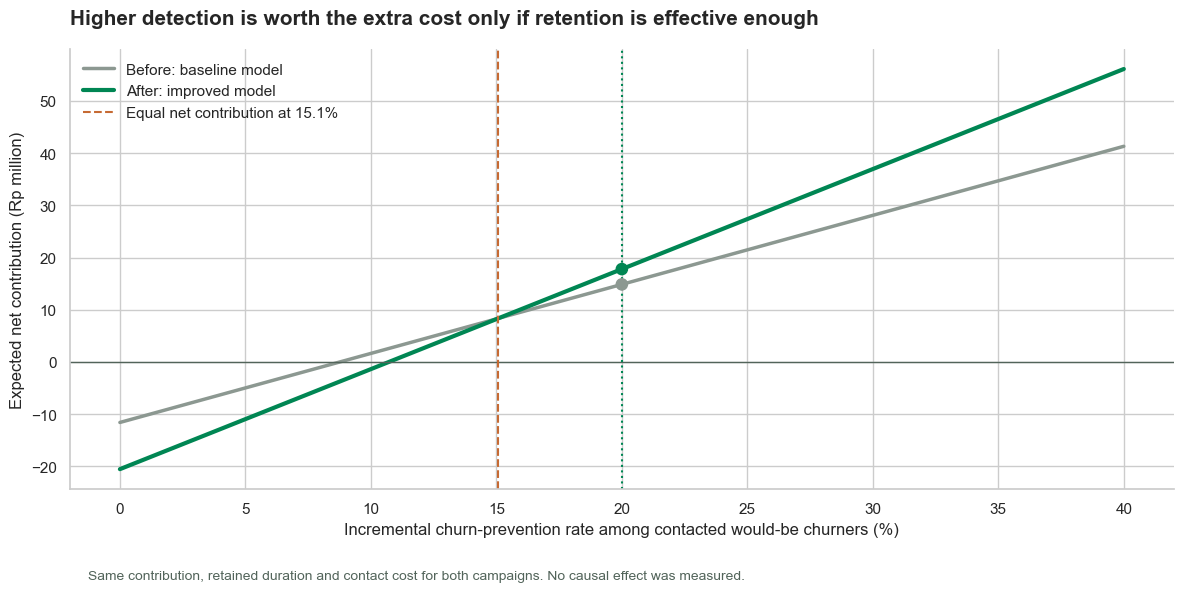

In [24]:
value_per_retained_customer = monthly_contribution_rp * additional_months_retained

before_break_even = before_business['Campaign cost (Rp)'] / (
    before_business['Actual churners identified'] * value_per_retained_customer
)
after_break_even = after_business['Campaign cost (Rp)'] / (
    after_business['Actual churners identified'] * value_per_retained_customer
)
extra_churners = after_business['Actual churners identified'] - before_business['Actual churners identified']

# The current result identifies more churners. Other outcomes need a different comparison.
if extra_churners > 0 and value_per_retained_customer > 0:
    improvement_break_even = extra_cost / (extra_churners * value_per_retained_customer)
else:
    improvement_break_even = np.nan

break_even_table = pd.DataFrame({
    'Question': ['Baseline campaign covers its cost',
                 'Improved campaign covers its cost',
                 'Improved campaign equals baseline net contribution'],
    'Required incremental prevention rate': [before_break_even, after_break_even, improvement_break_even]
})
display(break_even_table.style.format({'Required incremental prevention rate': '{:.2%}'}))

success_rates = np.linspace(0, 0.40, 81)
before_values = (before_business['Actual churners identified'] * success_rates * value_per_retained_customer
                 - before_business['Campaign cost (Rp)'])
after_values = (after_business['Actual churners identified'] * success_rates * value_per_retained_customer
                - after_business['Campaign cost (Rp)'])

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(success_rates * 100, before_values / 1_000_000,
        color='#8C9891', linewidth=2.5, label='Before: baseline model')
ax.plot(success_rates * 100, after_values / 1_000_000,
        color='#008653', linewidth=3, label='After: improved model')
ax.axhline(0, color='#52645A', linewidth=1)
ax.axvline(retention_success_rate * 100, color='#008653', linestyle=':', linewidth=1.5)
ax.scatter([retention_success_rate * 100] * 2, [before_net / 1_000_000, after_net / 1_000_000],
           color=['#8C9891', '#008653'], s=65, zorder=5)

if 0 <= improvement_break_even <= 0.40:
    ax.axvline(improvement_break_even * 100, color='#C66A33', linestyle='--', linewidth=1.5,
               label=f'Equal net contribution at {improvement_break_even:.1%}')

ax.set_title('Higher detection is worth the extra cost only if retention is effective enough',
             loc='left', fontsize=15, fontweight='bold', pad=18)
ax.set_xlabel('Incremental churn-prevention rate among contacted would-be churners (%)')
ax.set_ylabel('Expected net contribution (Rp million)')
ax.legend(loc='upper left', frameon=False)
ax.spines[['top', 'right']].set_visible(False)
fig.text(0.08, 0.02, 'Same contribution, retained duration and contact cost for both campaigns. No causal effect was measured.',
         fontsize=10, color='#52645A')
plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()

sensitivity_table = pd.DataFrame({
    'Incremental prevention rate': success_rates,
    'Before net contribution (Rp)': before_values,
    'After net contribution (Rp)': after_values,
    'Improvement (Rp)': after_values - before_values
})
sensitivity_table.to_csv('business_sensitivity_rupiah.csv', index=False)

### Interpretation and business recommendation

Under the demonstration inputs, the improved model supports a larger campaign. It reaches more would-be churners, but spends more on contacts and false positives. The net gain must include both effects.

The threshold remains selected for F1, not for profit. Neither this comparison nor the chart establishes the profit-maximizing threshold. In practice, different customers may have different contribution and responsiveness, and the two shortlists may respond differently.

Use a randomized retention pilot to measure the additional retention caused by outreach, then replace the assumptions with observed economics. Confirm the prediction window and that all features exist before churn. If outreach capacity is fixed, compare both models at the same contact budget as an additional analysis.

The following summary is calculated from the current inputs, so it updates when assumptions change.

In [25]:
print('BEFORE: baseline-model campaign')
print('Expected additional customers retained:', round(before_business['Expected additional customers retained'], 1))
print('Expected net contribution:', rupiah(before_net))
print()
print('AFTER: improved-model campaign')
print('Expected additional customers retained:', round(after_business['Expected additional customers retained'], 1))
print('Expected net contribution:', rupiah(after_net))
print()
print('Additional campaign expense:', rupiah(extra_cost))
print('Additional retained contribution:', rupiah(extra_contribution))
print('Change in expected net contribution:', rupiah(net_increase))
if not np.isnan(improvement_break_even):
    print('Equal net contribution between campaigns at prevention rate:', f'{improvement_break_even:.2%}')
print('These results are illustrative, not actual savings or a measured reduction in churn.')

BEFORE: baseline-model campaign
Expected additional customers retained: 29.4
Expected net contribution: Rp14.860.000

AFTER: improved-model campaign
Expected additional customers retained: 42.6
Expected net contribution: Rp17.790.000

Additional campaign expense: Rp8.950.000
Additional retained contribution: Rp11.880.000
Change in expected net contribution: Rp2.930.000
Equal net contribution between campaigns at prevention rate: 15.07%
These results are illustrative, not actual savings or a measured reduction in churn.


## 16. Rincian analisis biaya dan manfaat — Rp miliar

**Tujuan:** membandingkan manfaat bersih kampanye model awal dan model setelah perbaikan, termasuk biaya implementasi dan operasional.

Contoh ini menggunakan **100.000 pelanggan hipotetis untuk satu kampanye enam bulan**, bukan jumlah pelanggan pada dataset. Hasil 986 data uji diskalakan dengan faktor 100.000 / 986. Diasumsikan prevalensi churn, performa model, efektivitas intervensi, dan kontribusi pelanggan tetap sama. Seluruh harga dan volume kegiatan di bawah adalah **asumsi pembelajaran**, bukan penawaran vendor atau hasil bisnis aktual.

Nominal pada tabel dan grafik ditampilkan dalam **Rp miliar**. Angka input kode tetap dalam Rupiah agar mudah diedit. Rp1 miliar = Rp1.000.000.000. Perubahan unit tidak memperbesar hasil ekonomi. Kenaikan kontribusi kampanye pada 986 data uji sebelumnya hanya Rp0,00293 miliar.

### Komponen sederhana yang digunakan

| Kelompok | Item imajiner | Model awal | Setelah perbaikan | Alasan |
|---|---|---|---|---|
| Biaya langsung | Sewa komputasi | 6 bulan × Rp0,008 miliar | 6 bulan × Rp0,010 miliar | Menjalankan prediksi |
| Biaya langsung | Paket penyimpanan enam bulan | 1 × Rp0,012 miliar | 1 × Rp0,020 miliar | Menyimpan data dan hasil |
| Biaya langsung | Integrasi CRM | 100 jam × Rp0,0008 miliar | 125 jam × Rp0,0008 miliar | Memasukkan skor ke daftar kontak |
| Biaya langsung | Pelatihan petugas | 20 peserta × 2 jam × Rp0,0005 miliar | 30 peserta × 2 jam × Rp0,0005 miliar | Membaca dan memakai prediksi |
| Biaya langsung | Pemeliharaan | 6 hari-orang × Rp0,005 miliar | 8 hari-orang × Rp0,005 miliar | Memeriksa dan melatih ulang model selama enam bulan |
| Biaya langsung | Kontak dan penawaran | Jumlah TP + FP × Rp0,00005 miliar | Rumus sama | Semua pelanggan yang ditandai mendapat kontak |
| Biaya tidak langsung | Waktu adaptasi di luar pelatihan | 250 jam × Rp0,0001 miliar | 350 jam × Rp0,0001 miliar | Pekerjaan rutin yang tertunda |
| Biaya tidak langsung | Gangguan akibat salah sasaran | FP × Rp0,000001 miliar | Rumus sama | Nilai perkiraan waktu menangani keluhan tambahan |
| Manfaat langsung | Kontribusi pelanggan yang dipertahankan | TP × 20% × 6 bulan × Rp0,00015 miliar | Rumus sama | Kontribusi sesudah biaya layanan normal |
| Manfaat langsung | Penghematan seleksi manual | 500 jam × Rp0,00005 miliar | 800 jam × Rp0,00005 miliar | Waktu kerja yang benar-benar dapat dialihkan |
| Manfaat tidak langsung | Referral pelanggan baru | 20 pelanggan × Rp0,0003 miliar | 30 pelanggan × Rp0,0003 miliar | Kontribusi bersih pelanggan baru selama periode yang sama |

Referral adalah **contoh efek lanjutan yang belum terbukti**. Kontribusinya sudah dikurangi biaya akuisisi dan layanan, dan pelanggan referral berbeda dari pelanggan yang dipertahankan. Ubah `gunakan_referral = False` untuk mengeluarkannya dari perhitungan. Kepuasan dan loyalitas tetap kualitatif, tanpa tambahan nominal.

Pelatihan dibayar sebagai sesi peserta, sedangkan waktu adaptasi hanya mencakup pekerjaan di luar sesi tersebut. Biaya implementasi dan pelatihan dibebankan penuh pada periode pertama. Anggaran infrastruktur bukan bukti bahwa sistem mampu menangani volume tersebut.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

miliar = 1_000_000_000
gunakan_referral = True  # False: keluarkan manfaat referral yang belum terbukti.

# Satu baris = satu item. Biaya item = jumlah kegiatan × tarif per kegiatan.
# Untuk pelatihan, jumlah kegiatan adalah peserta × jam.
komponen = pd.DataFrame([
    ['Biaya langsung', 'Sewa komputasi', 'bulan', 6, 6, 8_000_000, 10_000_000],
    ['Biaya langsung', 'Penyimpanan enam bulan', 'paket', 1, 1, 12_000_000, 20_000_000],
    ['Biaya langsung', 'Integrasi CRM', 'jam', 100, 125, 800_000, 800_000],
    ['Biaya langsung', 'Pelatihan petugas', 'jam-peserta', 20*2, 30*2, 500_000, 500_000],
    ['Biaya langsung', 'Pemeliharaan', 'hari-orang', 6, 8, 5_000_000, 5_000_000],
    ['Biaya tidak langsung', 'Waktu adaptasi', 'jam', 250, 350, 100_000, 100_000],
    ['Manfaat langsung', 'Penghematan seleksi manual', 'jam', 500, 800, 50_000, 50_000],
    ['Manfaat tidak langsung', 'Referral pelanggan baru', 'pelanggan', 20, 30, 300_000, 300_000]
], columns=['Kelompok','Item','Satuan','Jumlah awal','Jumlah perbaikan','Tarif awal','Tarif perbaikan'])

komponen['Total awal'] = komponen['Jumlah awal'] * komponen['Tarif awal']
komponen['Total perbaikan'] = komponen['Jumlah perbaikan'] * komponen['Tarif perbaikan']
if not gunakan_referral:
    komponen.loc[komponen['Item']=='Referral pelanggan baru',['Total awal','Total perbaikan']] = 0

komponen.to_csv('rincian_komponen_rupiah.csv',index=False)
tampilan = komponen.copy()
for kolom in ['Tarif awal','Tarif perbaikan','Total awal','Total perbaikan']:
    tampilan[kolom] = tampilan[kolom] / miliar
print('Tarif dan total dalam Rp miliar; jumlah kegiatan tetap dalam satuan aslinya.')
display(tampilan.style.format({k:'{:.6f}' for k in ['Tarif awal','Tarif perbaikan','Total awal','Total perbaikan']}))

# Mengambil total item dengan cara sederhana.
def nilai_item(nama, kolom):
    return komponen.loc[komponen['Item']==nama, kolom].sum()

budget = pd.DataFrame(index=['Infrastructure','Implementation','Training','Maintenance',
                            'Staff transition opportunity cost','Productivity savings','Monetized indirect benefits'])
for skenario, kolom in [('Before','Total awal'),('After','Total perbaikan')]:
    budget[skenario] = [
        nilai_item('Sewa komputasi',kolom)+nilai_item('Penyimpanan enam bulan',kolom),
        nilai_item('Integrasi CRM',kolom),nilai_item('Pelatihan petugas',kolom),
        nilai_item('Pemeliharaan',kolom),nilai_item('Waktu adaptasi',kolom),
        nilai_item('Penghematan seleksi manual',kolom),nilai_item('Referral pelanggan baru',kolom)
    ]


Tarif dan total dalam Rp miliar; jumlah kegiatan tetap dalam satuan aslinya.


,Kelompok,Item,Satuan,Jumlah awal,Jumlah perbaikan,Tarif awal,Tarif perbaikan,Total awal,Total perbaikan
0,Biaya langsung,Sewa komputasi,bulan,6,6,0.008000,0.010000,0.048000,0.060000
1,Biaya langsung,Penyimpanan enam bulan,paket,1,1,0.012000,0.020000,0.012000,0.020000
2,Biaya langsung,Integrasi CRM,jam,100,125,0.000800,0.000800,0.080000,0.100000
3,Biaya langsung,Pelatihan petugas,jam-peserta,40,60,0.000500,0.000500,0.020000,0.030000
4,Biaya langsung,Pemeliharaan,hari-orang,6,8,0.005000,0.005000,0.030000,0.040000
5,Biaya tidak langsung,Waktu adaptasi,jam,250,350,0.000100,0.000100,0.025000,0.035000
6,Manfaat langsung,Penghematan seleksi manual,jam,500,800,0.000050,0.000050,0.025000,0.040000
7,Manfaat tidak langsung,Referral pelanggan baru,pelanggan,20,30,0.000300,0.000300,0.006000,0.009000


### Perlakuan biaya salah prediksi

**TP:** pelanggan yang memang churn dan berhasil ditandai. Manfaat baru muncul jika intervensi mencegah churn; asumsi efektivitasnya 20%.

**FP:** pelanggan yang sebetulnya bertahan, tetapi ditandai. Biaya kontak FP sudah termasuk biaya kampanye. Tambahan biaya tidak langsung hanya untuk penanganan gangguan/keluhan, bukan mengulang biaya kontak.

**FN:** pelanggan churn yang terlewat. Peluang kontribusi yang berpotensi diselamatkan = FN × 20% × kontribusi bulanan × enam bulan. Angka ini ditampilkan terpisah, tidak dikurangkan lagi dari manfaat bersih agar tidak menghitung kehilangan manfaat dua kali.

**TN:** pelanggan bertahan yang tidak ditandai. Tidak ada biaya kontak dalam kampanye ini.

Manfaat bersih = manfaat langsung + manfaat tidak langsung − biaya langsung − biaya tidak langsung. ROI = manfaat bersih / total biaya. Seluruh perhitungan adalah estimasi periode pertama, tanpa diskonto.

In [2]:

# Editable assumptions: all financial inputs below are in Rupiah.
rollout_customers = 100_000
test_customers = 986
prevention_rate = 0.20
monthly_contribution = 150_000
extra_months = 6
contact_offer_cost = 50_000
inconvenience_per_false_positive = 1_000
billion = 1_000_000_000

observed = pd.read_csv('business_impact_rupiah.csv')
factor = rollout_customers / test_customers
results = {}
for column, row_number in [('Before', 0), ('After', 1)]:
    row = observed.iloc[row_number]
    tp = row['Actual churners identified'] * factor
    fp = row['False positives contacted'] * factor
    fn = (263 - row['Actual churners identified']) * factor
    contacts = tp + fp
    retained = tp * prevention_rate
    contribution = retained * monthly_contribution * extra_months
    campaign = contacts * contact_offer_cost
    setup_running = budget.loc[['Infrastructure', 'Implementation', 'Training', 'Maintenance'], column].sum()
    direct_cost = campaign + setup_running
    indirect_cost = budget.loc['Staff transition opportunity cost', column] + fp * inconvenience_per_false_positive
    direct_benefit = contribution + budget.loc['Productivity savings', column]
    indirect_benefit = budget.loc['Monetized indirect benefits', column]
    total_cost = direct_cost + indirect_cost
    total_benefit = direct_benefit + indirect_benefit
    results[column] = {
        'Retained contribution': contribution, 'Productivity savings': budget.loc['Productivity savings', column],
        'Direct benefit': direct_benefit, 'Indirect benefit': indirect_benefit,
        'Campaign cost': campaign, 'Implementation and operating cost': setup_running,
        'Direct cost': direct_cost, 'Indirect cost': indirect_cost,
        'Total benefit': total_benefit, 'Total cost': total_cost,
        'Net benefit': total_benefit-total_cost,
        'False-positive contact cost (already included)': fp*contact_offer_cost,
        'False-negative opportunity (separate)': fn*prevention_rate*monthly_contribution*extra_months
    }

cba = pd.DataFrame(results)
cba['Change'] = cba['After'] - cba['Before']
cba.to_csv('cost_benefit_rupiah.csv')
print('Kampanye hipotetis enam bulan:', f'{rollout_customers:,}', 'pelanggan')
print('Seluruh nominal berikut dalam Rp miliar')
display((cba.rename(index={'Retained contribution': 'Kontribusi pelanggan dipertahankan', 'Productivity savings': 'Penghematan seleksi manual', 'Direct benefit': 'Manfaat langsung', 'Indirect benefit': 'Manfaat tidak langsung', 'Campaign cost': 'Biaya kontak dan penawaran', 'Implementation and operating cost': 'Biaya implementasi dan operasi', 'Direct cost': 'Biaya langsung', 'Indirect cost': 'Biaya tidak langsung', 'Total benefit': 'Total manfaat', 'Total cost': 'Total biaya', 'Net benefit': 'Manfaat bersih', 'False-positive contact cost (already included)': 'Biaya kontak FP (sudah masuk total)', 'False-negative opportunity (separate)': 'Peluang retensi FN (terpisah)'}, columns={'Before':'Model awal','After':'Model perbaikan','Change':'Selisih'}) / billion).style.format('{:.5f}'))
print('ROI model awal:', f"{cba.loc['Net benefit','Before']/cba.loc['Total cost','Before']:.1%}")
print('ROI model perbaikan:', f"{cba.loc['Net benefit','After']/cba.loc['Total cost','After']:.1%}")




Kampanye hipotetis enam bulan: 100,000 pelanggan
Seluruh nominal berikut dalam Rp miliar


,Model awal,Model perbaikan,Selisih
Kontribusi pelanggan dipertahankan,2.68357,3.88844,1.20487
Penghematan seleksi manual,0.02500,0.04000,0.01500
Manfaat langsung,2.70857,3.92844,1.21987
Manfaat tidak langsung,0.00600,0.00900,0.00300
Biaya kontak dan penawaran,1.17647,2.08418,0.90771
Biaya implementasi dan operasi,0.19000,0.25000,0.06000
Biaya langsung,1.36647,2.33418,0.96771
Biaya tidak langsung,0.03362,0.05508,0.02146
Total manfaat,2.71457,3.93744,1.22287
Total biaya,1.40009,2.38926,0.98917


ROI model awal: 93.9%
ROI model perbaikan: 64.8%


### Grafik perbandingan dan sensitivitas

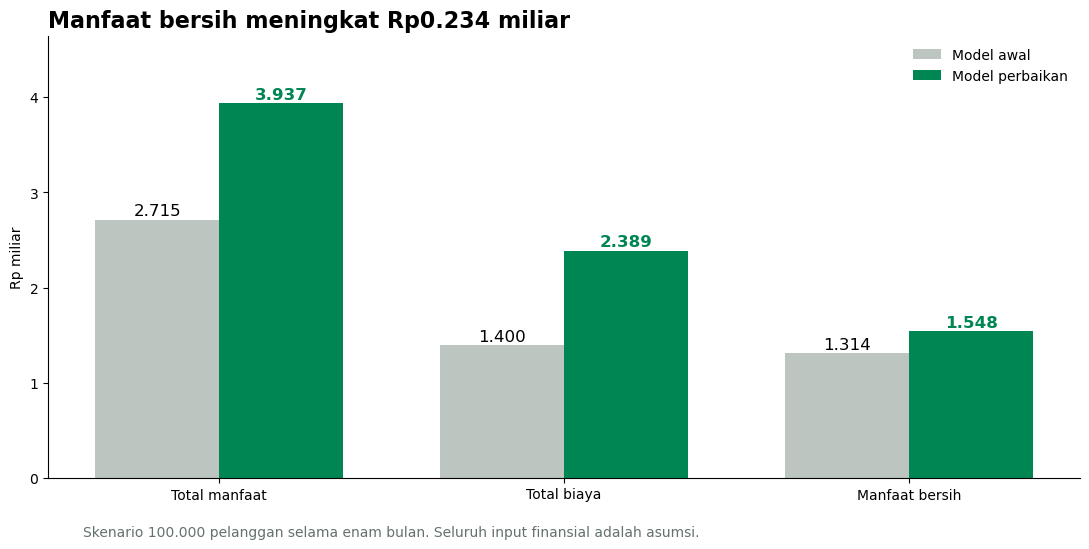

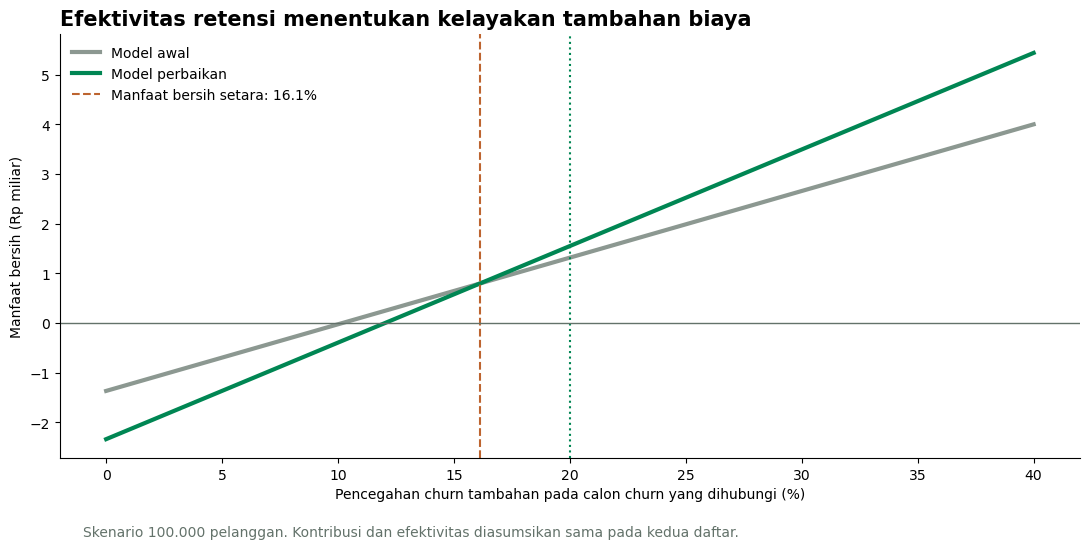

Efektivitas saat manfaat bersih kedua model setara: 16.12%


In [3]:
# Compare full costs and benefits, with net benefit highlighted.
fig, ax = plt.subplots(figsize=(11, 5.5))
positions = np.arange(3)
metrics = ['Total benefit', 'Total cost', 'Net benefit']
before = cba.loc[metrics, 'Before'].values / miliar
after = cba.loc[metrics, 'After'].values / miliar
ax.bar(positions-0.18, before, width=0.36, color='#BCC5C0', label='Model awal')
ax.bar(positions+0.18, after, width=0.36, color='#008653', label='Model perbaikan')
for x, b, a in zip(positions, before, after):
    ax.text(x-0.18, b+0.04, f'{b:.3f}', ha='center', fontsize=12)
    ax.text(x+0.18, a+0.04, f'{a:.3f}', ha='center', fontsize=12, color='#008653', fontweight='bold')
gain = cba.loc['Net benefit','Change']/billion
ax.set_title(f'Manfaat bersih meningkat Rp{gain:.3f} miliar',loc='left',fontweight='bold',fontsize=16)
ax.set_xticks(positions, ['Total manfaat', 'Total biaya', 'Manfaat bersih'])
ax.set_ylabel('Rp miliar')
ax.set_ylim(0,max(after.max(),before.max())*1.18)
ax.spines[['top','right']].set_visible(False)
ax.legend(frameon=False)
fig.text(0.08,0.015,'Skenario 100.000 pelanggan selama enam bulan. Seluruh input finansial adalah asumsi.',fontsize=10,color='#63726A')
fig.tight_layout(rect=[0,0.05,1,1])
fig.savefig('cost_benefit_comparison.png',dpi=160,bbox_inches='tight')
plt.show()

# Sensitivity includes full costs, unlike the earlier campaign-only calculation.
rates = np.linspace(0,0.4,81)
lines = {}
for col, i in [('Before',0),('After',1)]:
    retained_value = observed.iloc[i]['Actual churners identified']*factor*monthly_contribution*extra_months
    other_benefit = cba.loc['Productivity savings',col]+cba.loc['Indirect benefit',col]
    lines[col] = rates*retained_value + other_benefit - cba.loc['Total cost',col]
extra_value = (213-147)*factor*monthly_contribution*extra_months
extra_other_benefit = cba.loc['Productivity savings','Change']+cba.loc['Indirect benefit','Change']
equal_net_rate = (cba.loc['Total cost','Change']-extra_other_benefit)/extra_value
fig,ax=plt.subplots(figsize=(11,5.5))
for col,color in [('Before','#8C9891'),('After','#008653')]:
    ax.plot(rates*100,lines[col]/billion,label=('Model awal' if col=='Before' else 'Model perbaikan'),color=color,linewidth=3)
ax.axvline(equal_net_rate*100,color='#BD642F',linestyle='--',label=f'Manfaat bersih setara: {equal_net_rate:.1%}')
ax.axvline(prevention_rate*100,color='#008653',linestyle=':')
ax.axhline(0,color='#63726A',linewidth=1)
ax.set_title('Efektivitas retensi menentukan kelayakan tambahan biaya',loc='left',fontweight='bold',fontsize=15)
ax.set_xlabel('Pencegahan churn tambahan pada calon churn yang dihubungi (%)')
ax.set_ylabel('Manfaat bersih (Rp miliar)')
ax.spines[['top','right']].set_visible(False)
ax.legend(frameon=False)
fig.text(0.08,0.015,'Skenario 100.000 pelanggan. Kontribusi dan efektivitas diasumsikan sama pada kedua daftar.',fontsize=10,color='#63726A')
fig.tight_layout(rect=[0,0.05,1,1])
fig.savefig('cost_benefit_sensitivity.png',dpi=160,bbox_inches='tight')
plt.show()
print('Efektivitas saat manfaat bersih kedua model setara:',f'{equal_net_rate:.2%}')


### Interpretasi dan batas penggunaan

Manfaat bersih absolut dan ROI menjawab pertanyaan yang berbeda. Model perbaikan dapat menghasilkan manfaat bersih lebih besar sekaligus ROI lebih rendah karena membutuhkan lebih banyak biaya. Periksa keduanya bersama kapasitas kontak.

Jalankan kembali dengan `gunakan_referral = False` untuk skenario tanpa manfaat referral. Ubah juga efektivitas retensi, jumlah pelanggan, atau tarif untuk melihat pengaruhnya. Grafik sensitivitas memakai seluruh biaya, sehingga titik impas berbeda dari perhitungan kampanye sederhana pada Bagian 15.

Uji acak dengan kelompok kontrol diperlukan untuk mengukur retensi tambahan dan referral yang disebabkan program. Ganti seluruh asumsi dengan biaya dan kontribusi aktual sebelum menyetujui anggaran. Jangan menganggap pelanggan yang terdeteksi pasti berhasil dipertahankan. Jangan mengalikan hasil enam bulan menjadi tahunan tanpa memeriksa periode manfaat yang tumpang tindih.

## References and rerunning

The only dataset used is the supplied `data_telco_customer_churn.csv`. Keep it in the same folder as this notebook, or upload it to the current Colab session. Run the cells from top to bottom. All Python code and Markdown explanations are editable. No `assert` statements are used.

- [SciPy Shapiro–Wilk test](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.shapiro.html)
- [Statsmodels VIF](https://www.statsmodels.org/stable/generated/statsmodels.stats.outliers_influence.variance_inflation_factor.html)
- [Scikit-learn preprocessing](https://scikit-learn.org/stable/modules/preprocessing.html)
- [Imbalanced-learn: avoiding leakage during resampling](https://imbalanced-learn.org/stable/common_pitfalls.html)

Written interpretations describe the saved execution. If you change the data, random seed, features, or grids, update the interpretations to match the new output. The optional LightGBM method can be removed without rewriting the rest of the model-comparison loop.